In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error,r2_score,mean_absolute_error
from collections import defaultdict
import matplotlib.pyplot as plt

Transform value of column Smocker :   Yes to 1 and No to 0
Transform value of column Sex: male to 0  and female  to 1

In [4]:
def loaded_data():
     df=pd.read_csv("insurance.csv")
     df["smoker"]=df["smoker"].map({"yes":1,"no":0})
     df["sex"]=df["sex"].map({"male":0,"female":1})
     return df

In [5]:
df=loaded_data()
X = df.drop(columns=["charges","region"])
y = df["charges"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train, X_test, y_train, y_test)

      age  sex     bmi  children  smoker
560    46    1  19.950         2       0
1285   47    1  24.320         0       0
1142   52    1  24.860         0       0
969    39    1  34.320         5       0
486    54    1  21.470         3       0
...   ...  ...     ...       ...     ...
1095   18    1  31.350         4       0
1130   39    1  23.870         5       0
1294   58    0  25.175         0       0
860    37    1  47.600         2       1
1126   55    0  29.900         0       0

[1070 rows x 5 columns]       age  sex     bmi  children  smoker
764    45    1  25.175         2       0
887    36    1  30.020         0       0
890    64    1  26.885         0       1
1293   46    0  25.745         3       0
259    19    0  31.920         0       1
...   ...  ...     ...       ...     ...
109    63    0  35.090         0       1
575    58    1  27.170         0       0
535    38    0  28.025         1       0
543    54    1  47.410         0       1
846    51    1  34.200         1

In [6]:
model = LinearRegression()
features_choice={
   "Age":["age"],
   "Age+Smoker":["age","smoker"],
   "Smoker":["smoker"],
   "All_Collumns":X.columns.to_list()
}
data_dict=defaultdict(list)
print(features_choice)

{'Age': ['age'], 'Age+Smoker': ['age', 'smoker'], 'Smoker': ['smoker'], 'All_Collumns': ['age', 'sex', 'bmi', 'children', 'smoker']}


In [7]:

for name,feature in features_choice.items():
      X_train_choice=X_train[feature]
      X_test_choice=X_test[feature]
      model.fit(X_train_choice, y_train)
      y_pred=model.predict(X_test_choice)
      RMSE=root_mean_squared_error(y_test,y_pred)
      Mae=mean_absolute_error(y_test,y_pred)
      r2=r2_score(y_test,y_pred)
      data_dict["Regression with "].append(name)
      data_dict["RMSE"].append(RMSE)
      data_dict["MAE"].append(Mae) 
      data_dict["R²"].append(r2)
comparaison=pd.DataFrame(data_dict)
print(comparaison)

  Regression with           RMSE          MAE        R²
0              Age  11661.215952  9173.258197  0.124090
1       Age+Smoker   6186.654967  3990.979515  0.753462
2           Smoker   7262.641718  5625.810656  0.660249
3     All_Collumns   5829.172930  4213.484798  0.781130


without columns index 

In [8]:
print(comparaison.to_string(index=False))

Regression with          RMSE         MAE       R²
             Age 11661.215952 9173.258197 0.124090
      Age+Smoker  6186.654967 3990.979515 0.753462
          Smoker  7262.641718 5625.810656 0.660249
    All_Collumns  5829.172930 4213.484798 0.781130


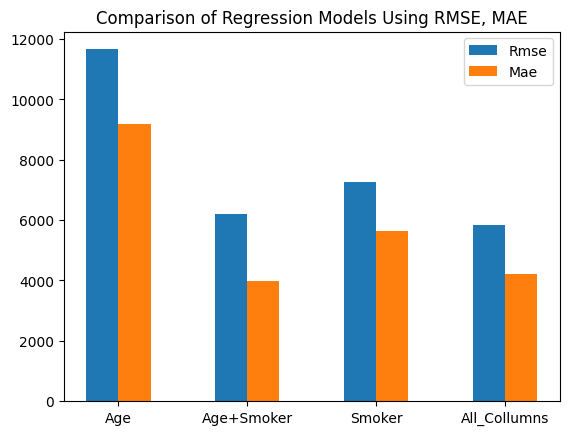

In [ ]:
import numpy as np
plt.title("Comparison of Regression Models Using RMSE, MAE")
x = np.arange(len(comparaison["Regression with "]))
width = 0.25
plt.bar(x -0.5*width, comparaison["RMSE"], width, label="Rmse")
plt.bar(x+0.5*width, comparaison["MAE"], width, label="Mae")
plt.xticks(x,comparaison["Regression with "])
plt.legend()
plt.show()


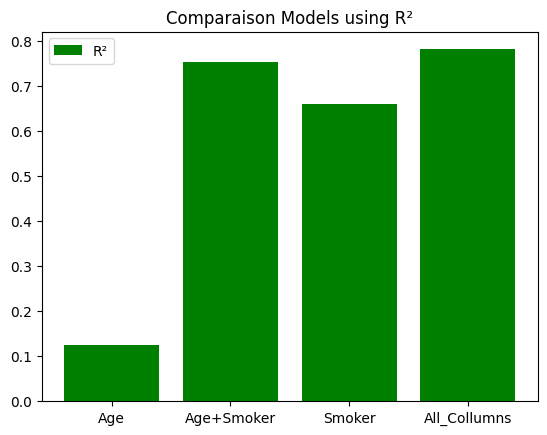

In [19]:
plt.bar(comparaison["Regression with "],comparaison["R²"],color="green",label="R²")
plt.legend()
plt.title("Comparaison Models using R²")
plt.show()